# One-zone model: nested sampling with UltraNest

Same one-zone model as the Minuit fit (June 2026 set-up), sampled with UltraNest instead of emcee, which also gives
the Bayesian evidence log Z. Runs for a few hours; the outputs shown are from my run, and the chains are in
`results/one_zone/ultranest_output_NuSTAR/`.

## Data and model

In [4]:
# Instead of loading prefit_model.pkl, rebuild from scratch
import dill
import numpy as np
from jetset.mcmc import McmcSampler
import matplotlib.pyplot as plt
from jetset.data_loader import ObsData
from jetset.obs_constrain import ObsConstrain
from jetset.sed_shaper import SEDShape
from jetset.model_manager import FitModel
from jetset.template_2Dmodel import EBLAbsorptionTemplate

from jetset.minimizer import ModelMinimizer

# Load data
sed_data = ObsData.load('results/one_zone/models/sed_data_unbinned.pkl')

# Rebuild SEDShape
my_shape = SEDShape(sed_data)
my_shape.eval_indices(silent=True)
my_shape.sync_fit(check_BBB_template=True, check_host_gal_template=False,
                  use_log_par=True, minimizer='lsb', fit_range=[9,16], silent=True)
my_shape.IC_fit(fit_range=[16,26], minimizer='minuit', silent=True)

# Rebuild prefit jet
sed_obspar = ObsConstrain(theta=3, bulk_factor=18.5, B_range=[0.02,0.08],
                          distr_e='bkn', t_var_sec=7*86400, nu_cut_IR=1E9,
                          SEDShape=my_shape)

prefit_jet = sed_obspar.constrain_SSC_EC_model(
    electron_distribution_log_values=False,
    EC_components_list=['EC_DT','EC_BLR','EC_Disk'],
    R_H=1.5E18, disk_type='MultiBB', silent=True
)

prefit_jet.set_par('L_Disk',   val=1.3817e46)
prefit_jet.set_par('M_BH',     val=9.8677e8)
prefit_jet.set_par('accr_eff', val=0.09)
prefit_jet.set_par('T_DT',     val=881.9)
prefit_jet.set_par('tau_DT',   val=0.1)
prefit_jet.set_par('tau_BLR',  val=0.1)

# Add theta_open dependency
prefit_jet.parameters.R_H.val = 1.5e18
prefit_jet.add_user_par(name='theta_open', val=3, units='deg')
prefit_jet.make_dependent_par(par='R', depends_on=['R_H','theta_open'],
                              par_expr='np.tan(np.radians(theta_open))*R_H')
prefit_jet.eval()

# Build FitModel + EBL
ebl = EBLAbsorptionTemplate.from_name('Franceschini_2008')
fit_model = FitModel(jet=prefit_jet, name='Final_Fit')
fit_model.add_component(ebl)
fit_model.link_par(par_name='z_cosm', from_model='Franceschini_2008', to_model='jet_leptonic')
fit_model.composite_expr = 'jet_leptonic * Franceschini_2008'
fit_model.jet_leptonic.set_num_c_threads(8)

fit_model.eval()
print(f'R_H = {prefit_jet.parameters.R_H.val:.3e}')
print(f'R   = {prefit_jet.parameters.R.val:.3e}')
print('Model rebuilt successfully.')


*** evaluating spectral indices for data ***


*** Log-Polynomial fitting of the synchrotron component ***
---> first blind fit run,  fit range: [9, 16]
---> class:  ISP

--> class:  LSP




model name,name,val,bestfit val,err +,err -,start val,fit range min,fit range max,frozen
LogParabolaEp,b,-8.256408e-02,-8.256408e-02,2.584721e-02,--,-6.224913e-02,-1.000000e+01,0.000000e+00,False
LogParabolaEp,Ep,1.330904e+01,1.330904e+01,5.717990e-01,--,1.413585e+01,0.000000e+00,3.000000e+01,False
LogParabolaEp,Sp,-1.333490e+01,-1.333490e+01,7.469589e-02,--,-1.320459e+01,-3.000000e+01,0.000000e+00,False
BBB,nuFnu_p_BBB,-1.338371e+01,-1.338371e+01,1.806069e-01,--,-1.320459e+01,-1.520459e+01,-1.120459e+01,False
BBB,nu_scale,4.312914e-02,4.312914e-02,6.422704e-03,--,0.000000e+00,-5.000000e-01,5.000000e-01,False


---> sync       nu_p=+1.330904e+01 (err=+5.717990e-01)  nuFnu_p=-1.333490e+01 (err=+7.469589e-02) curv.=-8.256408e-02 (err=+2.584721e-02)


*** Log-Polynomial fitting of the IC component ***
---> fit range: [16, 26]
---> LogCubic fit
====> simplex
====> migrad
====> simplex
====> migrad
====> simplex
====> migrad




model name,name,val,bestfit val,err +,err -,start val,fit range min,fit range max,frozen
LogCubic,b,-1.362857e-01,-1.362857e-01,2.137025e-02,--,-1.000000e+00,-1.000000e+01,0.000000e+00,False
LogCubic,c,-1.412340e-02,-1.412340e-02,3.894639e-03,--,-1.000000e+00,-1.000000e+01,1.000000e+01,False
LogCubic,Ep,2.206163e+01,2.206163e+01,1.234883e-01,--,2.324243e+01,0.000000e+00,3.000000e+01,False
LogCubic,Sp,-1.186960e+01,-1.186960e+01,1.075056e-01,--,-1.000000e+01,-3.000000e+01,0.000000e+00,False


---> IC         nu_p=+2.206163e+01 (err=+1.234883e-01)  nuFnu_p=-1.186960e+01 (err=+1.075056e-01) curv.=-1.362857e-01 (err=+2.137025e-02)


***  constrains parameters from observable ***

===> setting C threads to 8
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,R,region_size,cm,3.721835e+16,1.000000e+03,1.000000e+30,False,False
jet_leptonic,R_H,region_position,cm,1.500000e+18,0.000000e+00,--,False,True
jet_leptonic,B,magnetic_field,gauss,7.620413e-02,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_leptonic,theta,jet-viewing-angle,deg,3.000000e+00,0.000000e+00,9.000000e+01,False,False
jet_leptonic,BulkFactor,jet-bulk-factor,lorentz-factor*,1.850000e+01,1.000000e+00,1.000000e+05,False,False
jet_leptonic,z_cosm,redshift,,3.647763e+00,0.000000e+00,--,False,False
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,2.937958e+01,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,2.686264e+04,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,1.717180e+03,0.000000e+00,--,False,False




adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
adding par: z_cosm to  z_cosm
===> setting C threads to 8
R_H = 1.500e+18
R   = 7.861e+16
Model rebuilt successfully.


In [8]:
import numpy as np
import warnings
warnings.filterwarnings('ignore')
import ultranest
import ultranest.stepsampler
from jetset.data_loader import Data, ObsData
from jetset.model_manager import FitModel

## LOAD MINUIT MODEL AND SETUP FOR ULTRANEST

In [16]:
fit_model = dill.load(open('results/one_zone/models/minuit_model.pkl', 'rb'))
sed_data  = ObsData.load('results/one_zone/models/sed_data_unbinned.pkl')

# Freeze all
for par in fit_model.jet_leptonic.parameters.par_array:
    par.frozen = True

# Set frozen params to Minuit best-fit values
p = fit_model.jet_leptonic.parameters
p.p.val           = 1.590
p.p_1.val         = 3.066
p.gmin.val        = 2.101
p.gmax.val        = 1.653e4
p.gamma_break.val = 381.0
p.accr_eff.val    = 0.083

# 3 free parameters
free_params = ['B', 'M_BH', 'accr_eff']
prior_mins  = np.array([0.020, 5e8,  0.057])
prior_maxs  = np.array([0.150, 5e9,  0.300])

# 6 free parameters
#free_params = ['B', 'BulkFactor', 'N', 'M_BH', 'L_Disk', 'T_DT']
#for name in free_params:
#  fit_model.jet_leptonic.parameters.get_par_by_name(name).frozen = False

# Uniform prior bounds
#prior_mins = np.array([0.020, 10.0,  500.,  5e8,  1e46, 300.])
#prior_maxs = np.array([0.150, 25.0, 5000.,  5e9,  4e46, 1200.])

print(f'Free parameters: {free_params}')
for name, lo, hi in zip(free_params, prior_mins, prior_maxs):
    print(f'  {name:15s}: [{lo:.3e}, {hi:.3e}]')

===> setting C threads to 8
adding par: L_Disk to  R_DT
==> par R_DT is depending on ['L_Disk'] according to expr:   R_DT =
2E19*(L_Disk/1E46)**0.5
adding par: L_Disk to  R_BLR_in
==> par R_BLR_in is depending on ['L_Disk'] according to expr:   R_BLR_in =
3E17*(L_Disk/1E46)**0.5
adding par: R_BLR_in to  R_BLR_out
==> par R_BLR_out is depending on ['R_BLR_in'] according to expr:   R_BLR_out =
R_BLR_in*1.1
adding par: R_H to  R
adding par: theta_open to  R
==> par R is depending on ['R_H', 'theta_open'] according to expr:   R =
np.tan(np.radians(theta_open))*R_H
Free parameters: ['B', 'M_BH', 'accr_eff']
  B              : [2.000e-02, 1.500e-01]
  M_BH           : [5.000e+08, 5.000e+09]
  accr_eff       : [5.700e-02, 3.000e-01]


## PREPARE DATA ARRAYS AND LIKELIHOOD

In [17]:
nu_obs   = sed_data.table['nu_data'].data.astype(float)
flux_obs = sed_data.table['nuFnu_data'].data.astype(float)
flux_err = sed_data.table['dnuFnu_data'].data.astype(float)
is_ul    = sed_data.table['UL'].data.astype(bool)

print(f'Data: {len(nu_obs)} points, {is_ul.sum()} upper limits')

def get_composite_flux(nu_target):
    fit_model.eval()
    nu_grid   = fit_model.SED.nu.value
    flux_grid = fit_model.SED.nuFnu.value
    good = np.isfinite(flux_grid) & np.isfinite(nu_grid) & (nu_grid > 0)
    nu_g, fl_g = nu_grid[good], flux_grid[good]
    idx = np.argsort(nu_g)
    return np.interp(nu_target, nu_g[idx], fl_g[idx], left=0., right=0.)

def prior_transform(cube):
    return prior_mins + cube * (prior_maxs - prior_mins)

def log_likelihood(params):
    try:
        for name, val in zip(free_params, params):
            fit_model.jet_leptonic.set_par(name, val=val)
        model_flux = get_composite_flux(nu_obs)
        if np.any(~np.isfinite(model_flux)):
            return -1e100
        chi2 = 0.0
        for i in range(len(nu_obs)):
            if flux_err[i] <= 0:
                continue
            if is_ul[i]:
                if model_flux[i] > flux_obs[i]:
                    chi2 += ((model_flux[i] - flux_obs[i]) / flux_err[i])**2
            else:
                if model_flux[i] > 0:
                    chi2 += ((model_flux[i] - flux_obs[i]) / flux_err[i])**2
        return -0.5 * chi2 if np.isfinite(chi2) else -1e100
    except Exception:
        return -1e100

# Sanity check
best_fit_vals = np.array([
    fit_model.jet_leptonic.parameters.get_par_by_name(n).val
    for n in free_params
])
ll_test = log_likelihood(best_fit_vals)
print(f'logL at best-fit: {ll_test:.4f}  (should not be -1e100)')
assert ll_test > -1e99, 'Likelihood is broken — check model evaluation.'

Data: 45 points, 6 upper limits
logL at best-fit: -1573490836.6426  (should not be -1e100)


## RUN ULTRANEST

In [19]:
sampler = ultranest.ReactiveNestedSampler(
    param_names = free_params,
    loglike     = log_likelihood,
    transform   = prior_transform,
    log_dir     = 'results/one_zone/ultranest_output_NuSTAR',
    resume      = 'overwrite'   
)

sampler.stepsampler = ultranest.stepsampler.SliceSampler(
    nsteps             = 2 * len(free_params),
    generate_direction = ultranest.stepsampler.generate_mixture_random_direction
)

print(f'Running UltraNest: {len(free_params)} free parameters, 400 live points...')
results = sampler.run(
    min_num_live_points = 400,
    max_iters           = 200000,
    show_status         = True,
    viz_callback        = False
)
sampler.print_results()
print(f'\nlog Z = {results["logz"]:.3f} +/- {results["logzerr"]:.3f}')

Running UltraNest: 3 free parameters, 400 live points...
[ultranest] Sampling 400 live points from prior ...
[ultranest] Explored until L=-1e+01   [-13.4475..-13.4474]*| it/evals=4734/101502 eff=4.6824% N=400 0 
[ultranest] Likelihood function evaluations: 101502
[ultranest] Writing samples and results to disk ...
[ultranest] Writing samples and results to disk ... done
[ultranest]   logZ = -20.66 +- 0.07818
[ultranest] Effective samples strategy satisfied (ESS = 1910.9, need >400)
[ultranest] Posterior uncertainty strategy is satisfied (KL: 0.46+-0.09 nat, need <0.50 nat)
[ultranest] Evidency uncertainty strategy is satisfied (dlogz=0.08, need <0.5)
[ultranest]   logZ error budget: single: 0.12 bs:0.08 tail:0.01 total:0.08 required:<0.50
[ultranest] done iterating.

logZ = -20.656 +- 0.230
  single instance: logZ = -20.656 +- 0.120
  bootstrapped   : logZ = -20.665 +- 0.230
  tail           : logZ = +- 0.010
insert order U test : converged: True correlation: inf iterations
step sample

## POSTERIOR SUMMARY AND SAVE

In [20]:
samples  = results['samples']
post_med = np.median(samples, axis=0)
post_lo  = np.percentile(samples, 16, axis=0)
post_hi  = np.percentile(samples, 84, axis=0)

print('\n=== UltraNest posterior summary (median +/- 1sigma) ===')
for name, med, lo, hi in zip(free_params, post_med, post_lo, post_hi):
    print(f'  {name:15s}: {med:.4e}  +{hi-med:.4e}  -{med-lo:.4e}')
print(f'\nlog Z = {results["logz"]:.3f} +/- {results["logzerr"]:.3f}')

np.save('results/one_zone/models/ultranest_samples_1zone.npy', samples)
np.save('results/one_zone/models/ultranest_results_1zone.npy', results, allow_pickle=True)
print('Saved: ultranest_samples_1zone.npy')


=== UltraNest posterior summary (median +/- 1sigma) ===
  B              : 6.1342e-02  +4.0052e-03  -4.3255e-03
  M_BH           : 2.0675e+09  +3.5221e+08  -3.5635e+08
  accr_eff       : 7.9673e-02  +8.9945e-03  -7.2300e-03

log Z = -20.656 +/- 0.230
Saved: ultranest_samples_1zone.npy


## CORNER PLOT

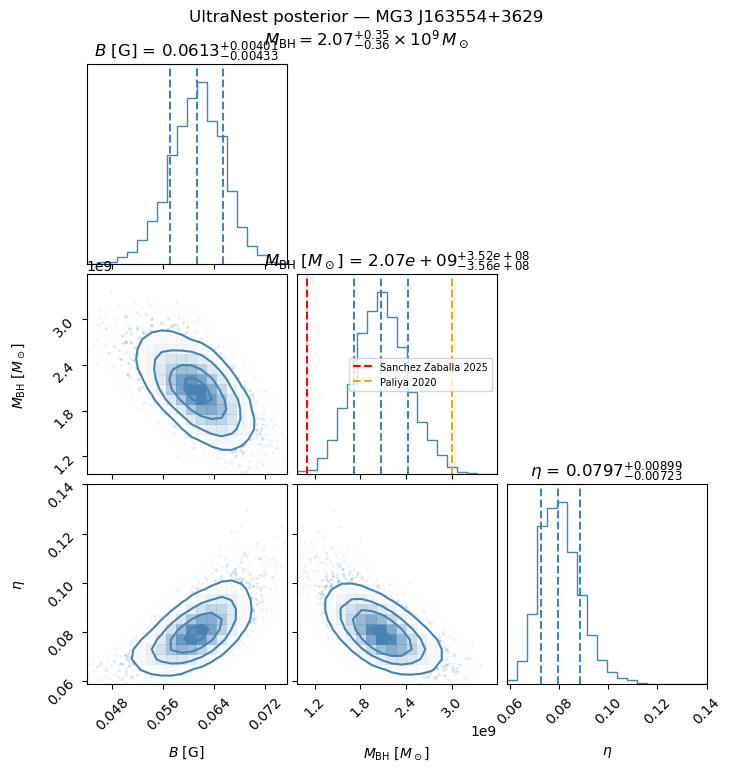

Saved: ultranest_corner_1zone.png


In [23]:
import corner

latex_labels = {
    'B':        r'$B$ [G]',
    'M_BH':     r'$M_{\rm BH}$ [$M_\odot$]',
    'accr_eff': r'$\eta$',
}
clabels = [latex_labels[n] for n in free_params]
clabels = [latex_labels[n] for n in free_params]
mbh_idx = free_params.index('M_BH')

fig = corner.corner(
    samples,
    labels=clabels,
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_fmt='.3g',
    color='steelblue',
    smooth=1.0
)

axes_arr = np.array(fig.axes).reshape(len(free_params), len(free_params))
ax_mbh = axes_arr[mbh_idx, mbh_idx]
ax_mbh.axvline(1.1e9, color='red',    lw=1.5, ls='--', label='Sanchez Zaballa 2025')
ax_mbh.axvline(3.0e9, color='orange', lw=1.5, ls='--', label='Paliya 2020')
ax_mbh.legend(fontsize=7)

mbh_med = np.median(samples[:, mbh_idx])
mbh_lo  = np.percentile(samples[:, mbh_idx], 16)
mbh_hi  = np.percentile(samples[:, mbh_idx], 84)

plt.suptitle(
    f'UltraNest posterior — MG3 J163554+3629\n'
    r'$M_{\rm BH} = ' + f'{mbh_med/1e9:.2f}'
    r'^{+' + f'{(mbh_hi-mbh_med)/1e9:.2f}' + r'}_{-' + f'{(mbh_med-mbh_lo)/1e9:.2f}' + r'}'
    r'\times 10^9\,M_\odot$',
    y=1.02, fontsize=12
)
plt.savefig('results/one_zone/plots/ultranest_corner_1zone.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: ultranest_corner_1zone.png')

## BEST-FIT SED (posterior median)

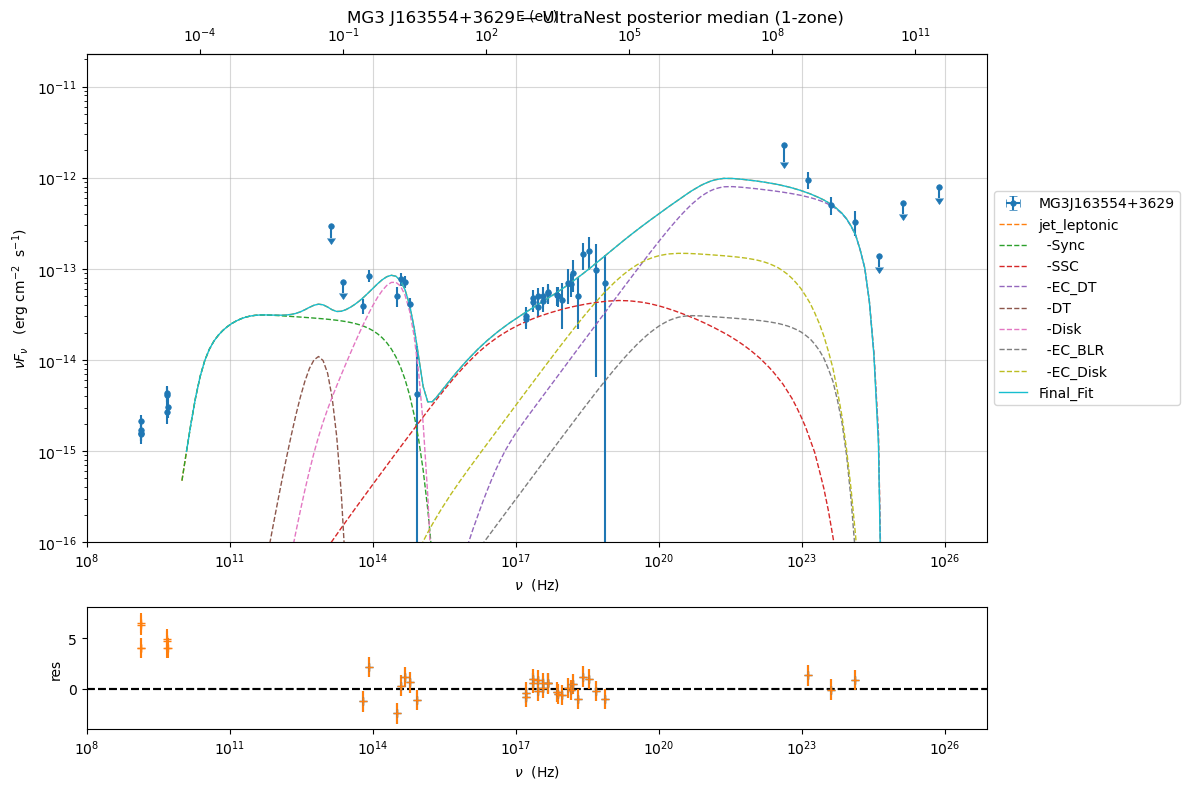

Saved: ultranest_bestfit_sed_1zone.png


In [24]:
for name, val in zip(free_params, post_med):
    fit_model.jet_leptonic.set_par(name, val=val)
fit_model.eval()

p = fit_model.plot_model(sed_data=sed_data)
p.add_residual_plot(fit_model, sed_data)
p.setlim(y_min=1e-16, x_min=1e8)
plt.suptitle('MG3 J163554+3629 — UltraNest posterior median (1-zone)')
plt.savefig('results/one_zone/plots/ultranest_bestfit_sed_1zone.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: ultranest_bestfit_sed_1zone.png')

## POSTERIOR ENVELOPE

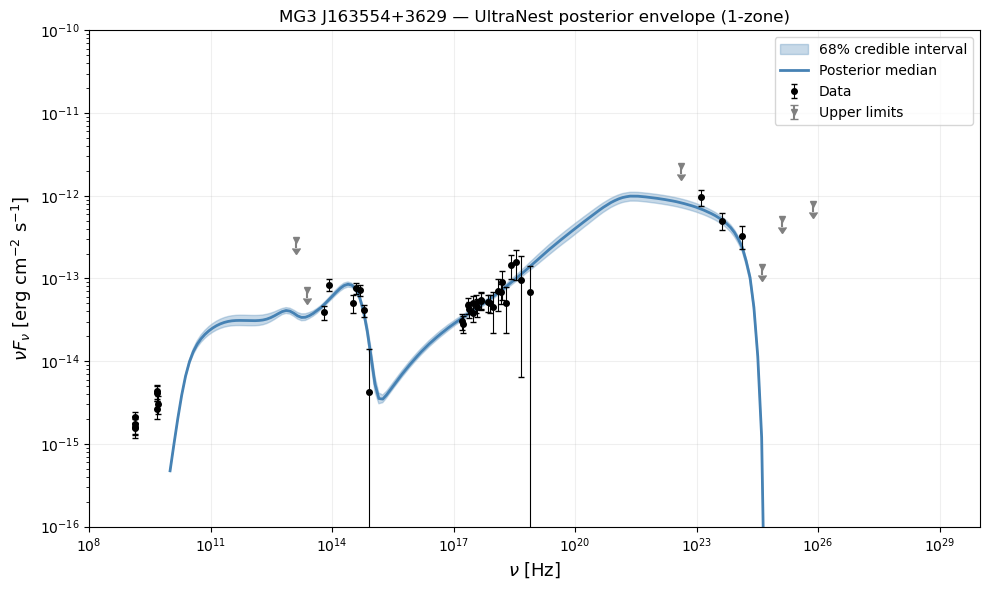


=== FINAL RESULT ===
M_BH  = 2.067e+09 +3.522e+08 -3.564e+08 M_sun
log Z = -20.656 +/- 0.230
Sanchez Zaballa (2025): 1.1e9 M_sun
Paliya et al.   (2020): 3.0e9 M_sun


In [25]:
n_draw   = 200
idx_draw = np.random.choice(len(samples), size=n_draw, replace=False)

nu_grid    = fit_model.SED.nu.value
all_fluxes = []

for i in idx_draw:
    for name, val in zip(free_params, samples[i]):
        fit_model.jet_leptonic.set_par(name, val=val)
    fit_model.eval()
    all_fluxes.append(fit_model.SED.nuFnu.value.copy())

all_fluxes = np.array(all_fluxes)
flux_lo    = np.percentile(all_fluxes, 16, axis=0)
flux_med   = np.percentile(all_fluxes, 50, axis=0)
flux_hi    = np.percentile(all_fluxes, 84, axis=0)
good       = flux_med > 0

fig, ax = plt.subplots(figsize=(10, 6))
ax.fill_between(nu_grid[good], flux_lo[good], flux_hi[good],
                alpha=0.3, color='steelblue', label='68% credible interval')
ax.loglog(nu_grid[good], flux_med[good],
          color='steelblue', lw=2, label='Posterior median')

det_mask = ~np.array(sed_data.table['UL'], dtype=bool)
ul_mask  =  np.array(sed_data.table['UL'], dtype=bool)
nu_d     = np.array(sed_data.table['nu_data'])
fl_d     = np.array(sed_data.table['nuFnu_data'])
err_d    = np.array(sed_data.table['dnuFnu_data'])

ax.errorbar(nu_d[det_mask], fl_d[det_mask], yerr=err_d[det_mask],
            fmt='o', color='black', ms=4, lw=0.8, capsize=2, label='Data')
ax.errorbar(nu_d[ul_mask], fl_d[ul_mask], yerr=fl_d[ul_mask]*0.2,
            fmt='v', color='gray', ms=4, uplims=True, label='Upper limits')

ax.set_xlim(1e8, 1e30); ax.set_ylim(1e-16, 1e-10)
ax.set_xlabel(r'$\nu$ [Hz]', fontsize=13)
ax.set_ylabel(r'$\nu F_\nu$ [erg cm$^{-2}$ s$^{-1}$]', fontsize=13)
ax.set_title('MG3 J163554+3629 — UltraNest posterior envelope (1-zone)', fontsize=12)
ax.legend(fontsize=10); ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.savefig('results/one_zone/plots/ultranest_envelope_1zone.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n=== FINAL RESULT ===')
print(f'M_BH  = {mbh_med:.3e} +{mbh_hi-mbh_med:.3e} -{mbh_med-mbh_lo:.3e} M_sun')
print(f'log Z = {results["logz"]:.3f} +/- {results["logzerr"]:.3f}')
print(f'Sanchez Zaballa (2025): 1.1e9 M_sun')
print(f'Paliya et al.   (2020): 3.0e9 M_sun')